# **House Price Prediction – Data Cleaning & Feature Encoding**

- **Author:** Abdallah Idris Benseghir
- **Year:** 2026
- **Month:** November
- **Project:** House Price Prediction

#### **Dataset**: [House Prices – Advanced Regression Techniques (Kaggle)](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)

#### **Notebook Description**

**File:** `03_Exploratory_Data_Analysis_and_Feature_Analysis.ipynb`

This notebook focuses on exploratory data analysis and numerical feature investigation to understand the dataset, identify potential outliers, and evaluate relationships between numerical features and the target variable (`SalePrice`).

#### **Main Operations**
- Load and inspect the cleaned training and testing datasets.
- Verify dataset dimensions and feature consistency.
- Generate statistical summaries of numerical features.
- Visualize potential outliers using boxplots.
- Detect outliers using the Interquartile Range (IQR) method.
- Analyse the distribution of `SalePrice` using histograms and boxplots.
- Calculate correlations between numerical features and `SalePrice`.
- Identify weakly correlated features using an absolute correlation threshold of 0.3.
- Visualize feature relationships using scatterplots and correlation heatmaps.
- Save low-correlation feature names for subsequent feature selection.

#### **Output Files**
- `final_feature_columns.txt`
- `selected_features.txt`

**Note:** This notebook focuses primarily on numerical feature analysis. Its findings will guide subsequent feature selection and model preparation.

##### **Section 1 – Library Imports**

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

##### **Section 2 – Dataset Loading**

In [2]:
# Define the dataset path
train_ds = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\clean_train.csv"
test_ds = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\clean_test.csv"

# Load the training dataset
train_df = pd.read_csv(train_ds)
test_df = pd.read_csv(test_ds)

##### **Section 3 – Feature Consistency Verification**

In [3]:
# Get column names
train_columns = set(train_df.columns)
test_columns = set(test_df.columns)

# Find differences
missing_in_test = train_columns - test_columns
missing_in_train = test_columns - train_columns

# Display results
print("Number of training columns:", len(train_df.columns))
print("Number of testing columns:", len(test_df.columns))

print("\nColumns missing from Testing Dataset:")
print(sorted(missing_in_test))

print("\nColumns missing from Training Dataset:")
print(sorted(missing_in_train))

# Final verification
if train_columns == test_columns:
    print("\nBoth datasets contain exactly the same column names.")
else:
    print("\nThe datasets have different column names.")

Number of training columns: 228
Number of testing columns: 228

Columns missing from Testing Dataset:
[]

Columns missing from Training Dataset:
[]

Both datasets contain exactly the same column names.


##### **Section 4 – Saving Final Feature Columns**

In [4]:
# Save column names if both datasets match
if train_columns == test_columns:

    with open(r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\final_feature_columns.txt", "w") as file:
        file.write("\n".join(train_df.columns))

    print("\nColumn names saved successfully!")

else:
    print("\nColumn names were not saved because the datasets differ.")


Column names saved successfully!


##### **Section 5 – Training Dataset Inspection**

In [5]:
# Display dataset dimensions (rows, columns)
print("Dataset Shape:", train_df.shape)

# Display the first five rows
print("\nDataset Preview:")
display(train_df.head())

# Display dataset information (columns, data types, non-null values)
print("\nDataset Information:")
train_df.info()

# Display statistical summary of numerical features
print("\nStatistical Summary:")
display(train_df.describe())

Dataset Shape: (1103, 228)

Dataset Preview:


,Id,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,255,20,70.0,8400,1,4,1,5,6,1957,...,0,0,0,1,0,0,0,0,1,0
1,1067,60,59.0,7837,1,3,1,6,7,1993,...,0,0,0,1,0,0,0,0,1,0
2,800,50,60.0,7200,1,4,1,5,7,1937,...,0,0,0,1,0,0,0,0,1,0
3,381,50,50.0,5000,1,4,1,5,6,1924,...,0,0,0,1,0,0,0,0,1,0
4,304,20,70.0,9800,1,4,1,5,7,1972,...,0,0,0,1,1,0,0,0,0,0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1103 entries, 0 to 1102
Columns: 228 entries, Id to SaleCondition_Partial
dtypes: float64(3), int64(225)
memory usage: 1.9 MB

Statistical Summary:


,Id,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
count,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000,...,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000,1103.000000
mean,731.373527,56.097008,70.805077,10877.097915,0.997280,3.566636,1.058024,6.207616,5.585675,1972.714415,...,0.003626,0.086129,0.000907,0.864007,0.059837,0.000907,0.005440,0.016319,0.830462,0.087035
std,424.732678,41.445880,22.503097,11021.958678,0.052105,0.597068,0.263107,1.329361,1.078436,29.748691,...,0.060138,0.280681,0.030110,0.342936,0.237292,0.030110,0.073587,0.126757,0.375396,0.282015
min,1.000000,20.000000,21.000000,1300.000000,0.000000,1.000000,1.000000,2.000000,2.000000,1880.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,362.000000,20.000000,60.000000,7760.500000,1.000000,3.000000,1.000000,5.000000,5.000000,1955.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,733.000000,50.000000,70.000000,9600.000000,1.000000,4.000000,1.000000,6.000000,5.000000,1975.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,1100.500000,70.000000,80.000000,11817.000000,1.000000,4.000000,1.000000,7.000000,6.000000,2001.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,1460.000000,190.000000,313.000000,215245.000000,1.000000,4.000000,3.000000,10.000000,9.000000,2010.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


##### **Section 6 – Testing Dataset Inspection**

In [6]:
# Display dataset dimensions (rows, columns)
print("Dataset Shape:", test_df.shape)

# Display the first five rows
print("\nDataset Preview:")
display(test_df.head())

# Display dataset information (columns, data types, non-null values)
print("\nDataset Information:")
test_df.info()

# Display statistical summary of numerical features
print("\nStatistical Summary:")
display(test_df.describe())

Dataset Shape: (275, 228)

Dataset Preview:


,Id,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,893,20,70.0,8414,1,4,1,6,8,1963,...,0,0,0,1,0,0,0,0,1,0
1,1106,60,98.0,12256,1,3,1,8,5,1994,...,0,0,0,1,0,0,0,0,1,0
2,414,30,56.0,8960,1,4,1,5,6,1927,...,0,0,0,1,0,0,0,0,1,0
3,523,50,50.0,5000,1,4,1,6,7,1947,...,0,0,0,1,0,0,0,0,1,0
4,1037,20,89.0,12898,1,3,1,9,5,2007,...,0,0,0,1,0,0,0,0,1,0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 275 entries, 0 to 274
Columns: 228 entries, Id to SaleCondition_Partial
dtypes: float64(3), int64(225)
memory usage: 490.0 KB

Statistical Summary:


,Id,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
count,275.000000,275.000000,275.000000,275.000000,275.000000,275.000000,275.000000,275.000000,275.000000,275.000000,...,275.0,275.000000,275.0,275.000000,275.000000,275.0,275.000000,275.000000,275.000000,275.000000
mean,731.552727,55.636364,69.560000,9972.185455,0.992727,3.632727,1.076364,6.109091,5.549091,1973.818182,...,0.0,0.090909,0.0,0.872727,0.076364,0.0,0.018182,0.007273,0.800000,0.098182
std,405.652705,39.423938,19.529106,5957.465526,0.085125,0.553375,0.316207,1.409984,1.094257,27.871244,...,0.0,0.288004,0.0,0.333886,0.266063,0.0,0.133852,0.085125,0.400729,0.298103
min,16.000000,20.000000,21.000000,1680.000000,0.000000,1.000000,1.000000,2.000000,2.000000,1880.000000,...,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
25%,373.500000,20.000000,60.000000,7500.000000,1.000000,3.000000,1.000000,5.000000,5.000000,1955.500000,...,0.0,0.000000,0.0,1.000000,0.000000,0.0,0.000000,0.000000,1.000000,0.000000
50%,734.000000,50.000000,70.000000,9084.000000,1.000000,4.000000,1.000000,6.000000,5.000000,1976.000000,...,0.0,0.000000,0.0,1.000000,0.000000,0.0,0.000000,0.000000,1.000000,0.000000
75%,1070.500000,70.000000,78.000000,11355.500000,1.000000,4.000000,1.000000,7.000000,6.000000,2000.000000,...,0.0,0.000000,0.0,1.000000,0.000000,0.0,0.000000,0.000000,1.000000,0.000000
max,1448.000000,190.000000,174.000000,70761.000000,1.000000,4.000000,3.000000,10.000000,9.000000,2009.000000,...,0.0,1.000000,0.0,1.000000,1.000000,0.0,1.000000,1.000000,1.000000,1.000000


##### **Section 7 – Numerical Outlier Visualization**

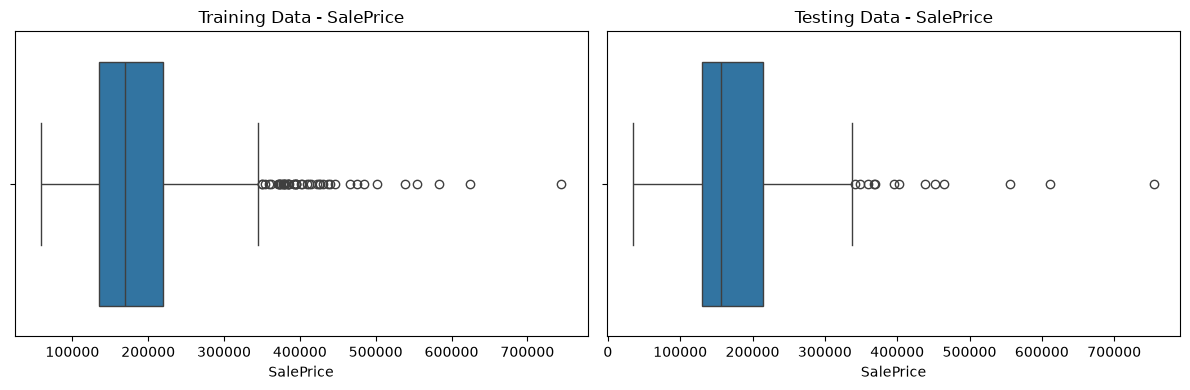

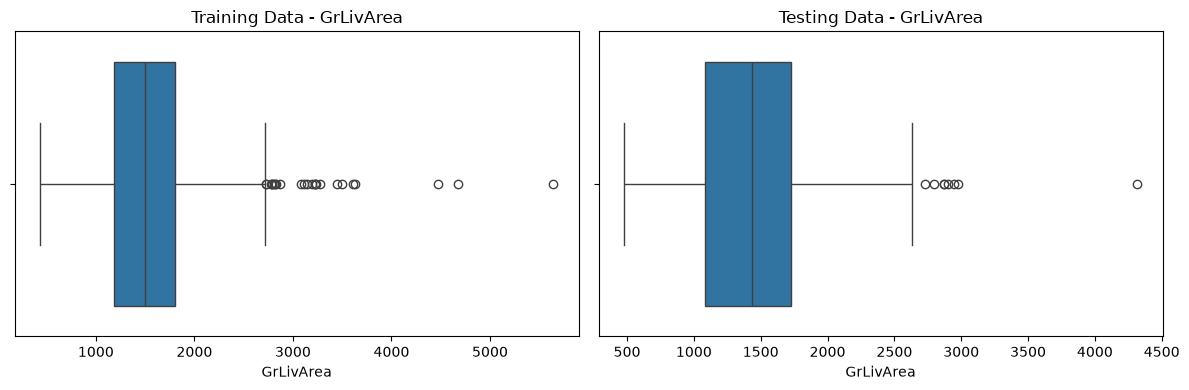

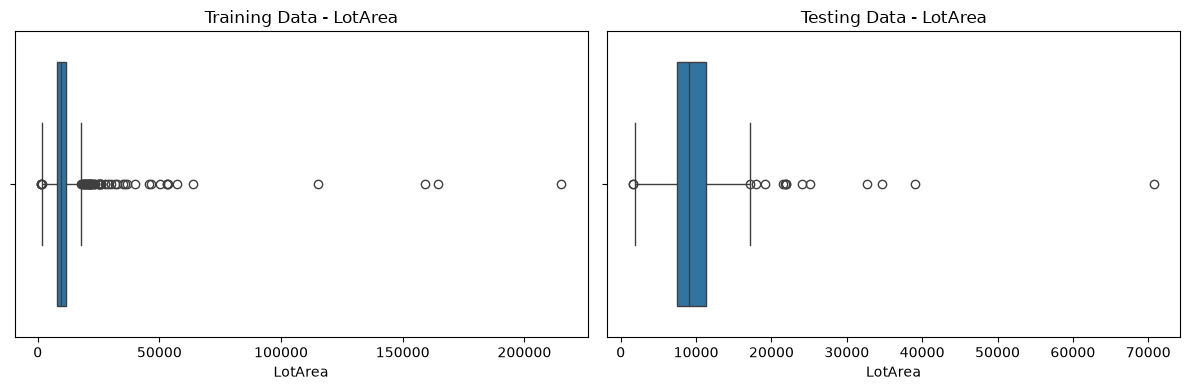

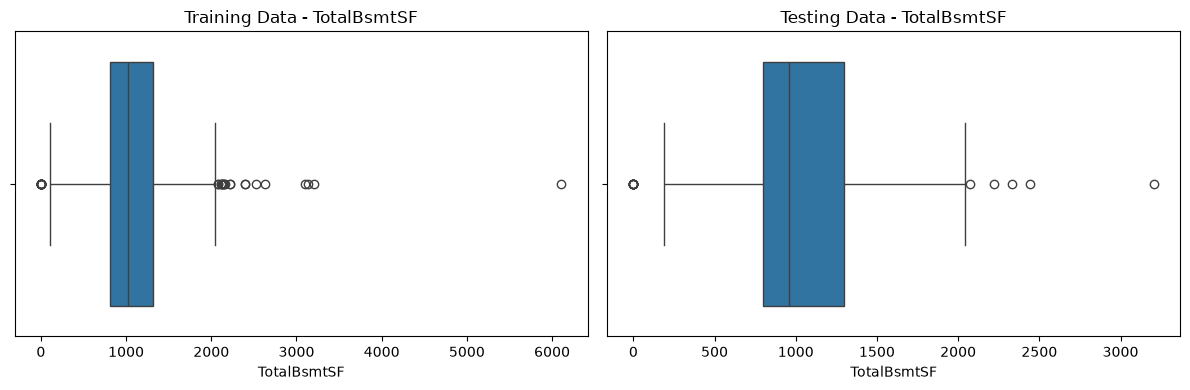

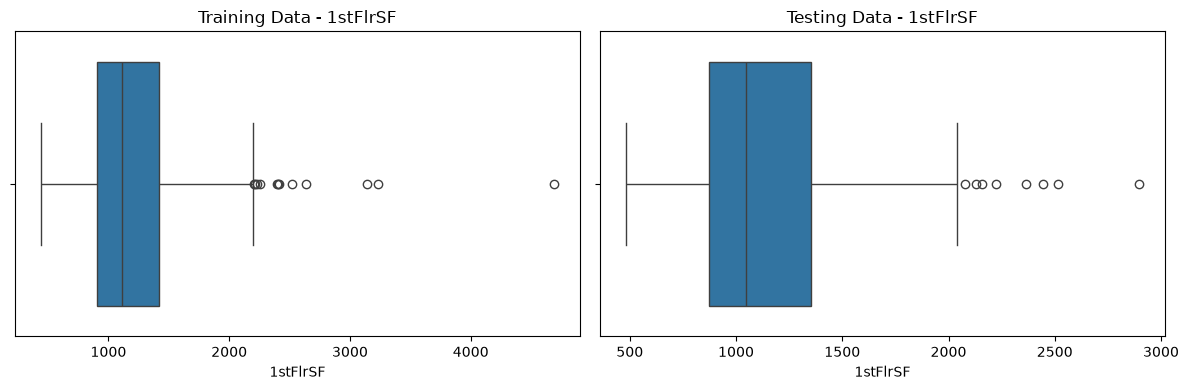

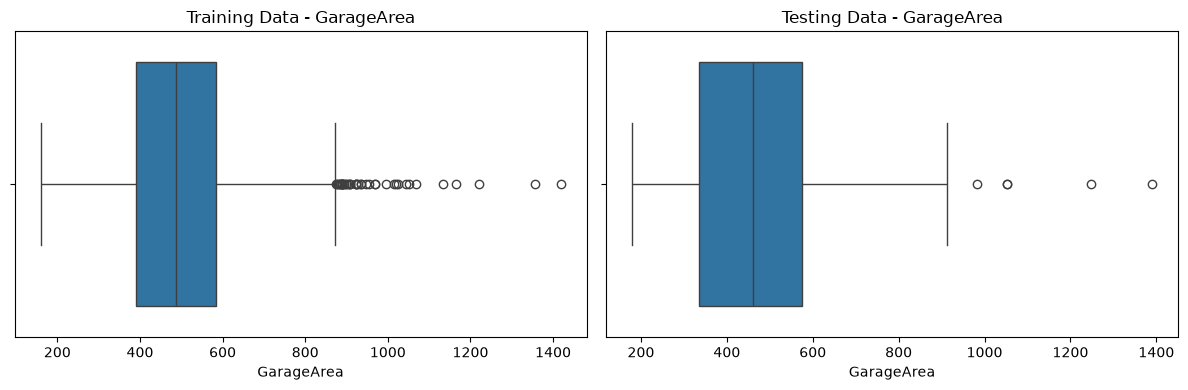

In [7]:
# Features to investigate for potential outliers
outlier_features = [
    "SalePrice",
    "GrLivArea",
    "LotArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "GarageArea"
]

# Generate training vs testing boxplots
for feature in outlier_features:

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    sns.boxplot(x=train_df[feature])
    plt.title(f"Training Data - {feature}")
    plt.xlabel(feature)

    plt.subplot(1, 2, 2)
    sns.boxplot(x=test_df[feature])
    plt.title(f"Testing Data - {feature}")
    plt.xlabel(feature)

    plt.tight_layout()
    plt.show()

##### **Section 8 – Outlier Detection Using the IQR Method**

In [8]:
# Calculate potential outliers using IQR
for feature in outlier_features:

    # Calculate IQR bounds using training data only
    Q1 = train_df[feature].quantile(0.25)
    Q3 = train_df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify training outliers
    train_outliers = train_df[
        (train_df[feature] < lower_bound) |
        (train_df[feature] > upper_bound)
    ]

    # Identify testing outliers using the same bounds
    test_outliers = test_df[
        (test_df[feature] < lower_bound) |
        (test_df[feature] > upper_bound)
    ]

    print(f"\nFeature: {feature}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Training Outliers:", len(train_outliers))
    print("Testing Outliers:", len(test_outliers))


Feature: SalePrice
Lower Bound: 8467.5
Upper Bound: 345887.5
Training Outliers: 45
Testing Outliers: 12

Feature: GrLivArea
Lower Bound: 263.0
Upper Bound: 2723.0
Training Outliers: 24
Testing Outliers: 8

Feature: LotArea
Lower Bound: 1675.75
Upper Bound: 17901.75
Training Outliers: 56
Testing Outliers: 12

Feature: TotalBsmtSF
Lower Bound: 57.0
Upper Bound: 2073.0
Training Outliers: 40
Testing Outliers: 14

Feature: 1stFlrSF
Lower Bound: 120.0
Upper Bound: 2204.0
Training Outliers: 12
Testing Outliers: 5

Feature: GarageArea
Lower Bound: 99.25
Upper Bound: 873.25
Training Outliers: 40
Testing Outliers: 11


##### **Section 9 – Outlier Removal**

In [9]:
# Create outlier masks
train_outlier_mask = pd.Series(False, index=train_df.index)
test_outlier_mask = pd.Series(False, index=test_df.index)

# Calculate IQR bounds using training data
for feature in outlier_features:

    Q1 = train_df[feature].quantile(0.25)
    Q3 = train_df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify training outliers
    train_feature_outliers = (
        (train_df[feature] < lower_bound) |
        (train_df[feature] > upper_bound)
    )

    # Identify testing outliers using the same bounds
    test_feature_outliers = (
        (test_df[feature] < lower_bound) |
        (test_df[feature] > upper_bound)
    )

    train_outlier_mask |= train_feature_outliers
    test_outlier_mask |= test_feature_outliers

    print(f"\nFeature: {feature}")
    print("Training outliers:", train_feature_outliers.sum())
    print("Testing outliers:", test_feature_outliers.sum())


# Remove outlier rows
train_df = train_df.loc[~train_outlier_mask].copy()
test_df = test_df.loc[~test_outlier_mask].copy()


# Display final dataset shapes
print("\nDatasets after outlier removal:")
print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)


Feature: SalePrice
Training outliers: 45
Testing outliers: 12

Feature: GrLivArea
Training outliers: 24
Testing outliers: 8

Feature: LotArea
Training outliers: 56
Testing outliers: 12

Feature: TotalBsmtSF
Training outliers: 40
Testing outliers: 14

Feature: 1stFlrSF
Training outliers: 12
Testing outliers: 5

Feature: GarageArea
Training outliers: 40
Testing outliers: 11

Datasets after outlier removal:
Training dataset shape: (954, 228)
Testing dataset shape: (231, 228)


##### **Section 10 – SalePrice Statistical Analysis**

In [10]:
# Display descriptive statistics of house prices

print("TRAINING DATA - SalePrice:")
display(train_df["SalePrice"].describe())

print("TESTING DATA - SalePrice:")
display(test_df["SalePrice"].describe())

TRAINING DATA - SalePrice:


count       954.000000
mean     173594.214885
std       55429.693813
min       58500.000000
25%      133925.000000
50%      164250.000000
75%      204000.000000
max      345000.000000
Name: SalePrice, dtype: float64

TESTING DATA - SalePrice:


count       231.000000
mean     167649.203463
std       58568.911927
min       35311.000000
25%      129950.000000
50%      154300.000000
75%      196000.000000
max      337500.000000
Name: SalePrice, dtype: float64

##### **Section 11 – SalePrice Distribution Visualization**

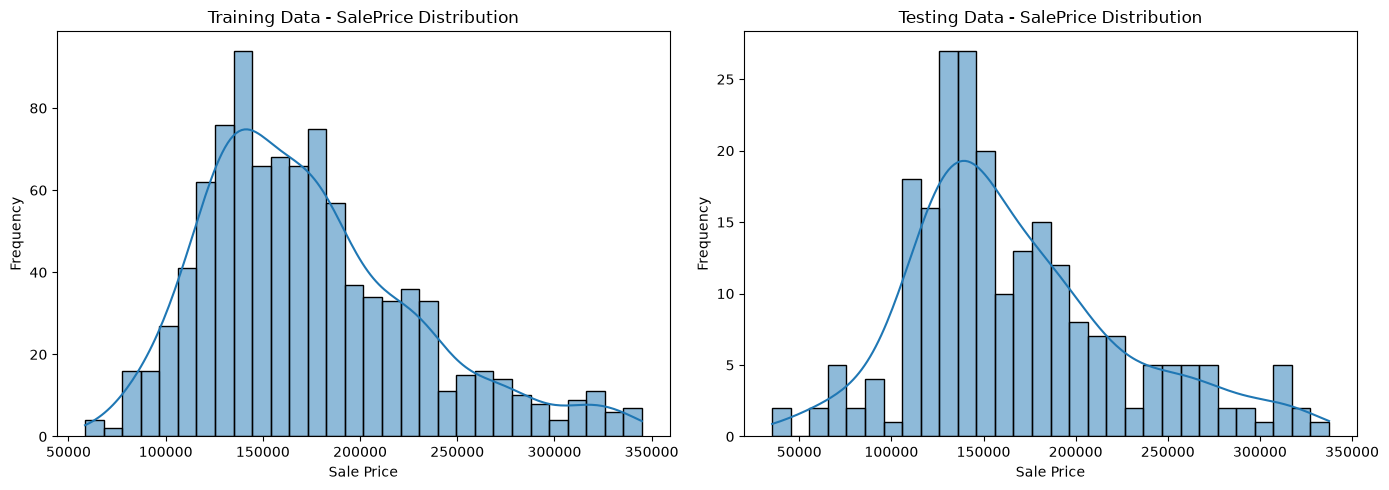

In [11]:
# Visualize training and testing distributions side by side
plt.figure(figsize=(14, 5))

# Training distribution
plt.subplot(1, 2, 1)
sns.histplot(
    data=train_df,
    x="SalePrice",
    kde=True,
    bins=30
)
plt.title("Training Data - SalePrice Distribution")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

# Testing distribution
plt.subplot(1, 2, 2)
sns.histplot(
    data=test_df,
    x="SalePrice",
    kde=True,
    bins=30
)
plt.title("Testing Data - SalePrice Distribution")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

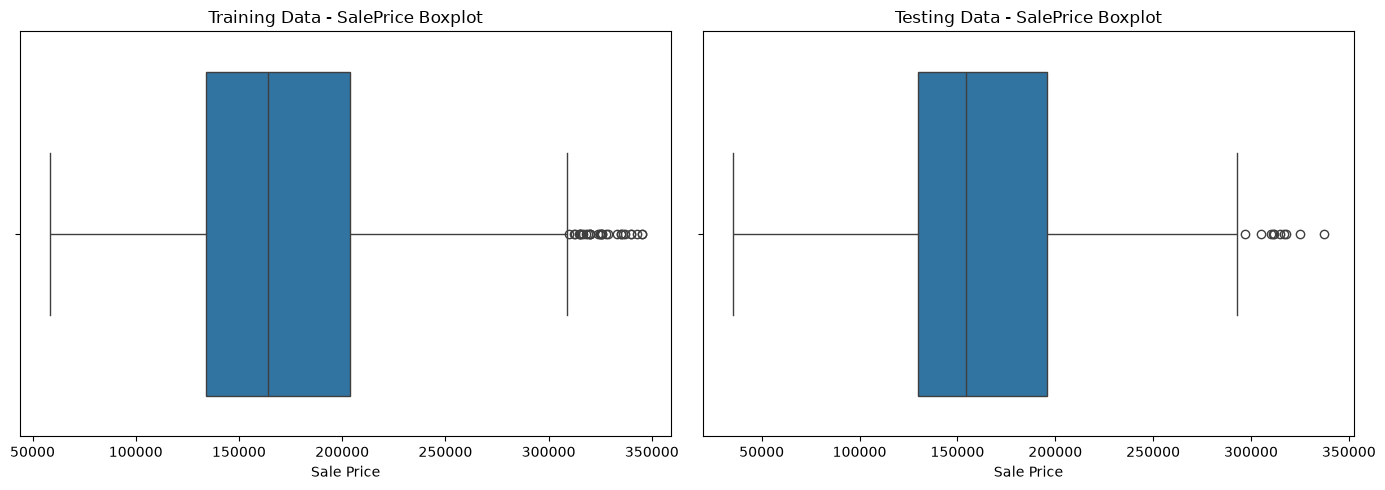

In [12]:
# Visualize training and testing boxplots side by side
plt.figure(figsize=(14, 5))

# Training boxplot
plt.subplot(1, 2, 1)
sns.boxplot(x=train_df["SalePrice"])
plt.title("Training Data - SalePrice Boxplot")
plt.xlabel("Sale Price")

# Testing boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x=test_df["SalePrice"])
plt.title("Testing Data - SalePrice Boxplot")
plt.xlabel("Sale Price")

plt.tight_layout()
plt.show()

##### **Section 12 – Numerical Feature Identification**

In [13]:
# Define dataset folder
folder = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques"

# Read numerical feature names
with open(folder + r"\numerical_features.txt", "r") as file:
    numerical_cols = file.read().splitlines()

# Keep numerical features available in both datasets
numerical_cols = [
    col for col in numerical_cols
    if col in train_df.columns and col in test_df.columns
]

# Include SalePrice as the target
correlation_cols = numerical_cols

# Calculate correlations
train_corr = train_df[correlation_cols].corr()["SalePrice"].drop("SalePrice")
test_corr = test_df[correlation_cols].corr()["SalePrice"].drop("SalePrice")

# Combine correlations into one DataFrame
correlation_comparison = pd.DataFrame({
    "Training Correlation": train_corr,
    "Testing Correlation": test_corr
})

# Sort by absolute training correlation
correlation_comparison = correlation_comparison.loc[
    correlation_comparison["Training Correlation"].abs().sort_values(
        ascending=False
    ).index
]

# Display results
display(correlation_comparison)

,Training Correlation,Testing Correlation
OverallQual,0.787619,0.804088
GrLivArea,0.672511,0.738039
GarageCars,0.619460,0.647005
GarageArea,0.604742,0.664680
YearBuilt,0.589266,0.617839
FullBath,0.583093,0.631902
YearRemodAdd,0.560510,0.573187
TotalBsmtSF,0.552930,0.616212
GarageYrBlt,0.537685,0.570260
1stFlrSF,0.522851,0.604188


##### **Section 14 – Low-Correlation Feature Identification**

In [14]:
# Select features with absolute correlation less than 0.3
selected_features = correlation_comparison[
    correlation_comparison["Training Correlation"].abs() < 0.3
].index.tolist()

print("Number of selected features:", len(selected_features))

print("\nFeatures with Absolute Correlation < 0.3:")
print(selected_features)

# Save selected feature names into a text file
with open(folder + r"\selected_features.txt", "w") as file:
    file.write("\n".join(selected_features))

print("\nSelected features saved successfully!")

Number of selected features: 21

Features with Absolute Correlation < 0.3:
['WoodDeckSF', '2ndFlrSF', 'HalfBath', 'BsmtFinSF1', 'BsmtUnfSF', 'EnclosedPorch', 'BsmtFullBath', 'BedroomAbvGr', 'KitchenAbvGr', 'OverallCond', 'ScreenPorch', 'LowQualFinSF', 'BsmtHalfBath', 'MoSold', 'MSSubClass', 'BsmtFinSF2', 'Id', 'MiscVal', '3SsnPorch', 'YrSold', 'PoolArea']

Selected features saved successfully!


##### **Section 15 – Feature Relationship Visualization**



In [15]:
# Calculate the number of selected features
n_features = len(selected_features)

# Create subplots (3 plots per row)
fig, axes = plt.subplots(
    n_features,
    2,
    figsize=(14, 5 * n_features)
)

# Flatten axes for easier iteration
axes = np.array(axes).reshape(n_features, 2)

# Generate side-by-side scatter plots for each selected feature
for i, feature in enumerate(selected_features):

    # Training dataset
    sns.scatterplot(
        data=train_df,
        x=feature,
        y="SalePrice",
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"Training Data - {feature} vs SalePrice")

    # Testing dataset
    sns.scatterplot(
        data=test_df,
        x=feature,
        y="SalePrice",
        ax=axes[i, 1]
    )
    axes[i, 1].set_title(f"Testing Data - {feature} vs SalePrice")

plt.tight_layout()
plt.show()

##### **Section 16 – Correlation Matrix Visualization**

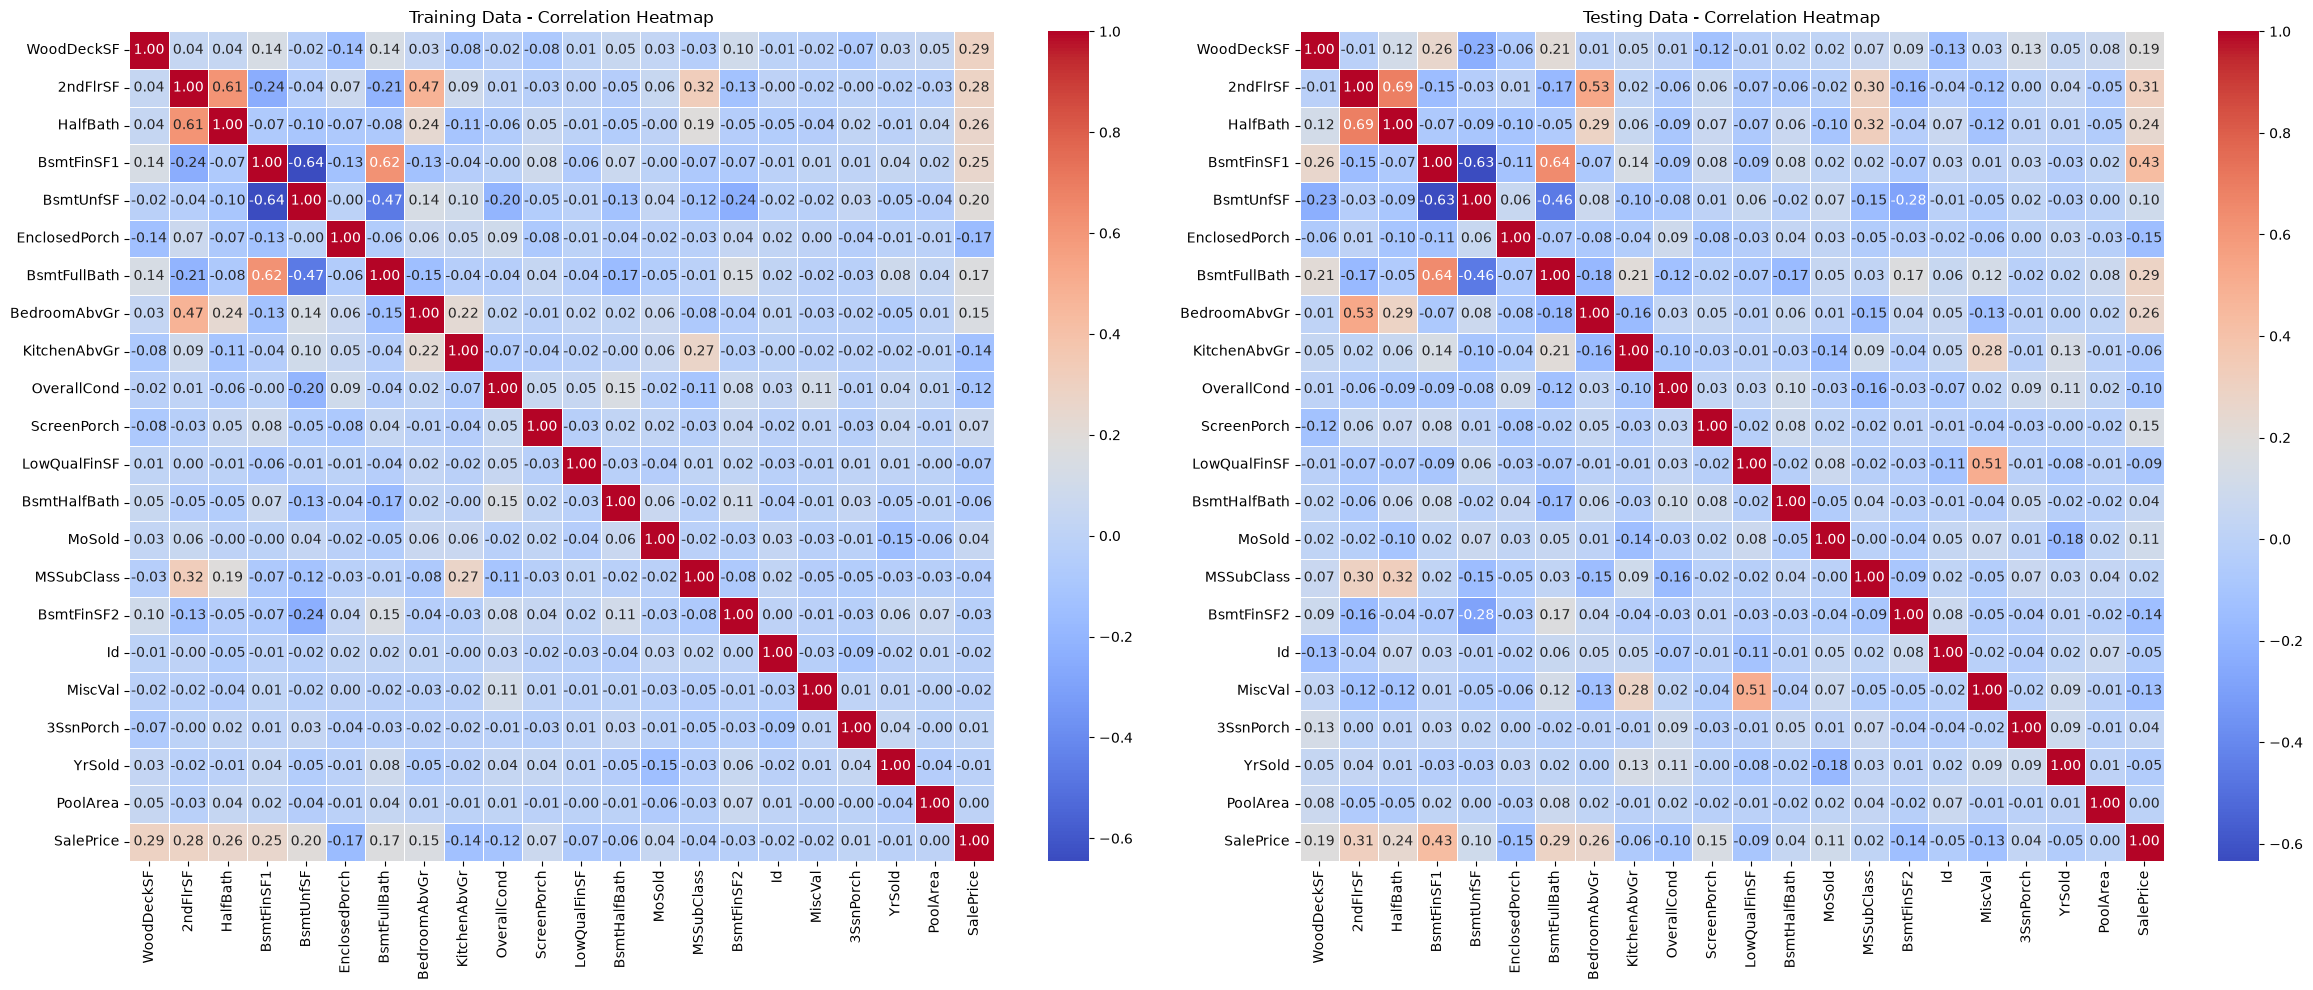

In [16]:
# Include SalePrice in the correlation matrix
selected_features.append("SalePrice")

# Calculate correlation matrices for both datasets
train_correlation_matrix = train_df[selected_features].corr()
test_correlation_matrix = test_df[selected_features].corr()

# Create side-by-side heatmaps
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

# Training dataset
sns.heatmap(
    train_correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    ax=axes[0]
)
axes[0].set_title("Training Data - Correlation Heatmap")

# Testing dataset
sns.heatmap(
    test_correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    ax=axes[1]
)
axes[1].set_title("Testing Data - Correlation Heatmap")

plt.tight_layout()
plt.show()